# AWS SBG Tasks - Week 01: Small Python Data-Processing App

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eyustarX/aws-sbg-tasks/blob/main/week-01/data_processing.ipynb)

## 📋 Task Overview
In this assignment, we build an end-to-end data pipeline that:
1. **Loads** a raw sales dataset with missing values, invalid types, and duplicate entries.
2. **Cleans** the dataset using modular Python functions.
3. **Processes** the cleaned numbers with **NumPy** (vectorized arithmetic, financial metrics, normalization, and statistical summaries).
4. **Visualizes** key metrics using `matplotlib`.
5. Runs seamlessly in both local Jupyter and Google Colab.

### Step 1: Environment Setup & Library Imports
We import NumPy, Pandas, Matplotlib, and standard file utilities.

In [1]:
from io import StringIO
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(f"NumPy Version: {np.__version__}")
print(f"Pandas Version: {pd.__version__}")

NumPy Version: 2.5.4
Pandas Version: 3.0.6


### Step 2: Load the Raw Dataset
We read from `data/raw_sales_data.csv`. If running standalone inside Google Colab without cloning the full repository, an embedded fallback CSV is used automatically.

In [2]:
FALLBACK_CSV = """order_id,date,product,category,unit_price,quantity,discount_pct,city
1001,2024-01-05,Laptop,Electronics,1200,2,0.1,New York
1002,2024-01-06,Wireless Mouse,Electronics,25,10,0.05,Los Angeles
1003,2024-01-08,Desk Chair,Furniture,150,3,,Chicago
1004,2024-01-10,USB Cable,Electronics,12,-2,0,Houston
1005,2024-01-12,Mechanical Keyboard,Electronics,85,4,0.15,
1006,2024-01-15,Coffee Mug,Kitchen,15,5,0,New York
1007,2024-01-18,Gaming Monitor,Electronics,300,N/A,0.1,San Francisco
1008,2024-01-20,Office Desk,Furniture,,1,0.05,Austin
1009,2024-01-22,Desk Lamp,Furniture,45,3,0,Seattle
1010,2024-01-25,Water Bottle,Kitchen,20,8,0.2,Los Angeles
1001,2024-01-05,Laptop,Electronics,1200,2,0.1,New York
1011,2024-01-28,Headphones,Electronics,90,5,0.1,Chicago
1012,2024-01-30,Standing Desk,Furniture,400,2,,Houston"""

csv_path = Path("data/raw_sales_data.csv")
if csv_path.exists():
    raw_df = pd.read_csv(csv_path)
else:
    raw_df = pd.read_csv(StringIO(FALLBACK_CSV))

print(f"Raw dataset shape: {raw_df.shape}")
raw_df

Raw dataset shape: (13, 8)


,order_id,date,product,category,unit_price,quantity,discount_pct,city
0,1001,2024-01-05,Laptop,Electronics,1200.0,2.0,0.10,New York
1,1002,2024-01-06,Wireless Mouse,Electronics,25.0,10.0,0.05,Los Angeles
2,1003,2024-01-08,Desk Chair,Furniture,150.0,3.0,NaN,Chicago
3,1004,2024-01-10,USB Cable,Electronics,12.0,-2.0,0.00,Houston
4,1005,2024-01-12,Mechanical Keyboard,Electronics,85.0,4.0,0.15,NaN
5,1006,2024-01-15,Coffee Mug,Kitchen,15.0,5.0,0.00,New York
6,1007,2024-01-18,Gaming Monitor,Electronics,300.0,NaN,0.10,San Francisco
7,1008,2024-01-20,Office Desk,Furniture,NaN,1.0,0.05,Austin
8,1009,2024-01-22,Desk Lamp,Furniture,45.0,3.0,0.00,Seattle
9,1010,2024-01-25,Water Bottle,Kitchen,20.0,8.0,0.20,Los Angeles


### Step 3: Data Cleaning with Modular Functions
We define isolated functions for each cleaning step:
- `remove_duplicates`: removes duplicate orders.
- `sanitize_numerical_columns`: coerces strings (like 'N/A') to `NaN` and removes negative counts.
- `handle_missing_values`: replaces missing discounts with `0.0` and unknown cities with `'Unknown'`.

In [3]:
def remove_duplicates(df: pd.DataFrame, subset=None) -> pd.DataFrame:
    """Deduplicate records based on order identifier."""
    return df.drop_duplicates(subset=subset).reset_index(drop=True)

def sanitize_numerical_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Parse numbers and filter out negative / erroneous values."""
    cleaned = df.copy()
    for col in ["unit_price", "quantity", "discount_pct"]:
        cleaned[col] = pd.to_numeric(cleaned[col], errors="coerce")
    # Discard non-positive prices and quantities
    cleaned = cleaned[(cleaned["quantity"] > 0) & (cleaned["unit_price"] > 0)]
    return cleaned.reset_index(drop=True)

def handle_missing_values(df: pd.DataFrame) -> pd.DataFrame:
    """Impute sensible defaults for missing fields."""
    cleaned = df.copy()
    cleaned["discount_pct"] = cleaned["discount_pct"].fillna(0.0)
    cleaned["city"] = cleaned["city"].fillna("Unknown")
    cleaned = cleaned.dropna(subset=["order_id", "product", "unit_price", "quantity"])
    cleaned["order_id"] = cleaned["order_id"].astype(int)
    cleaned["quantity"] = cleaned["quantity"].astype(int)
    return cleaned.reset_index(drop=True)

def clean_pipeline(df: pd.DataFrame) -> pd.DataFrame:
    """Execute full cleaning workflow."""
    s1 = remove_duplicates(df, subset=["order_id"])
    s2 = sanitize_numerical_columns(s1)
    return handle_missing_values(s2)

cleaned_df = clean_pipeline(raw_df)
print(f"Cleaned dataset shape: {cleaned_df.shape}")
cleaned_df

Cleaned dataset shape: (9, 8)


,order_id,date,product,category,unit_price,quantity,discount_pct,city
0,1001,2024-01-05,Laptop,Electronics,1200.0,2,0.10,New York
1,1002,2024-01-06,Wireless Mouse,Electronics,25.0,10,0.05,Los Angeles
2,1003,2024-01-08,Desk Chair,Furniture,150.0,3,0.00,Chicago
3,1005,2024-01-12,Mechanical Keyboard,Electronics,85.0,4,0.15,Unknown
4,1006,2024-01-15,Coffee Mug,Kitchen,15.0,5,0.00,New York
5,1009,2024-01-22,Desk Lamp,Furniture,45.0,3,0.00,Seattle
6,1010,2024-01-25,Water Bottle,Kitchen,20.0,8,0.20,Los Angeles
7,1011,2024-01-28,Headphones,Electronics,90.0,5,0.10,Chicago
8,1012,2024-01-30,Standing Desk,Furniture,400.0,2,0.00,Houston


### Step 4: Numerical Processing with NumPy
We extract NumPy arrays for high-performance vectorized operations:
- Gross Revenue = $\text{unit\_price} \times \text{quantity}$
- Net Revenue = $\text{gross\_revenue} \times (1 - \text{discount\_pct})$
- Min-Max Normalization: scaled to $[0, 1]$
- Z-Score Standardization: normalized with $\mu = 0, \sigma = 1$

In [4]:
# Convert to NumPy 1D arrays
prices = cleaned_df["unit_price"].to_numpy(dtype=np.float64)
quantities = cleaned_df["quantity"].to_numpy(dtype=np.float64)
discounts = cleaned_df["discount_pct"].to_numpy(dtype=np.float64)

# NumPy vectorized arithmetic
gross_revenue = prices * quantities
discount_amount = gross_revenue * discounts
net_revenue = gross_revenue - discount_amount

# NumPy Min-Max scaling
norm_revenue = (net_revenue - np.min(net_revenue)) / (np.max(net_revenue) - np.min(net_revenue))

# NumPy Z-score standardization
z_scores = (net_revenue - np.mean(net_revenue)) / np.std(net_revenue)

# Enrich DataFrame
processed_df = cleaned_df.copy()
processed_df["gross_revenue"] = gross_revenue
processed_df["net_revenue"] = net_revenue
processed_df["normalized_revenue"] = np.round(norm_revenue, 3)
processed_df["z_score"] = np.round(z_scores, 3)
processed_df

,order_id,date,product,category,unit_price,quantity,discount_pct,city,gross_revenue,net_revenue,normalized_revenue,z_score
0,1001,2024-01-05,Laptop,Electronics,1200.0,2,0.10,New York,2400.0,2160.0,1.000,2.661
1,1002,2024-01-06,Wireless Mouse,Electronics,25.0,10,0.05,Los Angeles,250.0,237.5,0.078,-0.458
2,1003,2024-01-08,Desk Chair,Furniture,150.0,3,0.00,Chicago,450.0,450.0,0.180,-0.113
3,1005,2024-01-12,Mechanical Keyboard,Electronics,85.0,4,0.15,Unknown,340.0,289.0,0.103,-0.375
4,1006,2024-01-15,Coffee Mug,Kitchen,15.0,5,0.00,New York,75.0,75.0,0.000,-0.722
5,1009,2024-01-22,Desk Lamp,Furniture,45.0,3,0.00,Seattle,135.0,135.0,0.029,-0.625
6,1010,2024-01-25,Water Bottle,Kitchen,20.0,8,0.20,Los Angeles,160.0,128.0,0.025,-0.636
7,1011,2024-01-28,Headphones,Electronics,90.0,5,0.10,Chicago,450.0,405.0,0.158,-0.186
8,1012,2024-01-30,Standing Desk,Furniture,400.0,2,0.00,Houston,800.0,800.0,0.348,0.454


### Step 5: Statistical Distribution Analysis via NumPy
We compute key statistical metrics using built-in NumPy mathematical functions.

In [5]:
print("=== Summary Statistics (NumPy Computations) ===")
print(f"Total Revenue  : ${np.sum(net_revenue):,.2f}")
print(f"Mean Revenue   : ${np.mean(net_revenue):,.2f}")
print(f"Median Revenue : ${np.median(net_revenue):,.2f}")
print(f"Std Deviation  : ${np.std(net_revenue):,.2f}")
print(f"Minimum Revenue: ${np.min(net_revenue):,.2f}")
print(f"Maximum Revenue: ${np.max(net_revenue):,.2f}")
print(f"25th Percentile: ${np.percentile(net_revenue, 25):,.2f}")
print(f"75th Percentile: ${np.percentile(net_revenue, 75):,.2f}")

=== Summary Statistics (NumPy Computations) ===
Total Revenue  : $4,679.50
Mean Revenue   : $519.94
Median Revenue : $289.00
Std Deviation  : $616.37
Minimum Revenue: $75.00
Maximum Revenue: $2,160.00
25th Percentile: $135.00
75th Percentile: $450.00


### Step 6: Visualizations with Matplotlib
We plot our computed net revenues and prices to inspect distribution and product performance.

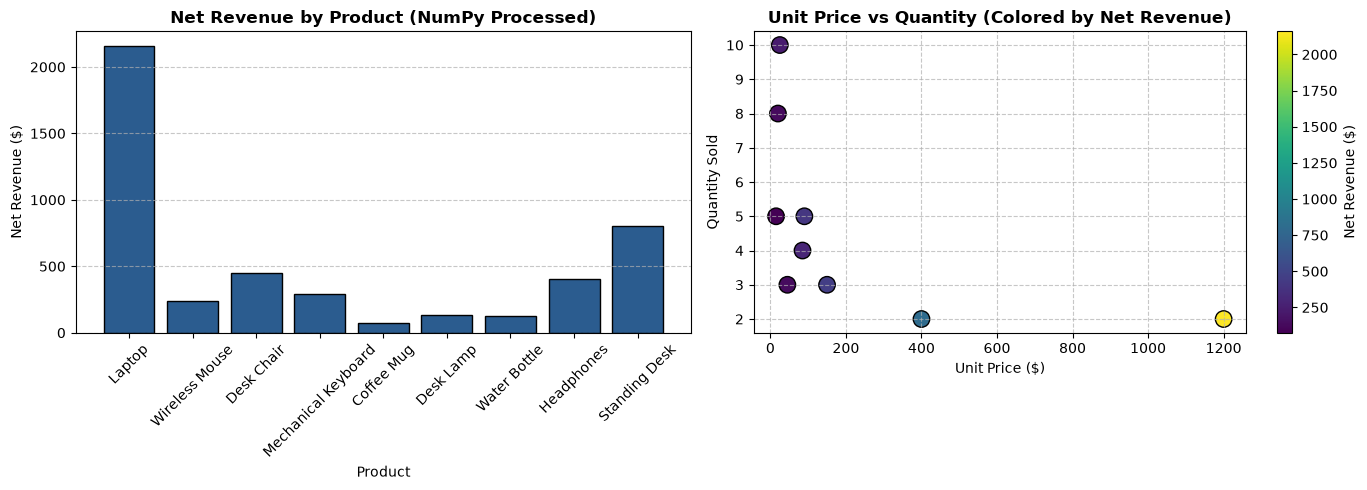

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Net Revenue per Product
ax[0].bar(processed_df["product"], processed_df["net_revenue"], color="#2b5c8f", edgecolor="black")
ax[0].set_title("Net Revenue by Product (NumPy Processed)", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Product")
ax[0].set_ylabel("Net Revenue ($)")
ax[0].tick_params(axis="x", rotation=45)
ax[0].grid(axis="y", linestyle="--", alpha=0.7)

# Plot 2: Unit Price vs Quantity Sold
scatter = ax[1].scatter(
    processed_df["unit_price"],
    processed_df["quantity"],
    c=processed_df["net_revenue"],
    cmap="viridis",
    s=140,
    edgecolors="black"
)
cbar = plt.colorbar(scatter, ax=ax[1])
cbar.set_label("Net Revenue ($)")
ax[1].set_title("Unit Price vs Quantity (Colored by Net Revenue)", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Unit Price ($)")
ax[1].set_ylabel("Quantity Sold")
ax[1].grid(True, linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

### Step 7: Export Processed Dataset
We save the final clean dataset so it can be used for downstream analysis.

In [7]:
output_dir = Path("data")
output_dir.mkdir(exist_ok=True)
processed_df.to_csv(output_dir / "processed_sales_data.csv", index=False)
print("Successfully saved processed dataset to data/processed_sales_data.csv!")

Successfully saved processed dataset to data/processed_sales_data.csv!
